In [1]:
# CELL 1: Setup & Dataset Download
import os
import json
import kagglehub
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Downloads once, then loads from local cache offline!
raw_path = kagglehub.dataset_download("emmarex/plantdisease")
print("Local dataset path:", raw_path)

# Locate the exact folder containing the 15 crop disease class subfolders
data_dir = raw_path
for root, dirs, files in os.walk(raw_path):
    if len(dirs) >= 10 and "PlantVillage" not in dirs:
        data_dir = root
        break

print(f"Dataset directory set to: {data_dir}")
print(f"Total classes found: {len(os.listdir(data_dir))}")

d:\Project\Crop Disease Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


100%|██████████| 658M/658M [03:12<00:00, 3.59MB/s] 

Extracting files...


Local dataset path: C:\Users\TUSHAR\.cache\kagglehub\datasets\emmarex\plantdisease\versions\1
Dataset directory set to: C:\Users\TUSHAR\.cache\kagglehub\datasets\emmarex\plantdisease\versions\1\PlantVillage\PlantVillage
Total classes found: 15


In [2]:
# CELL 2: Data Preprocessing & DataLoaders
IMAGE_SIZE = 128
BATCH_SIZE = 64

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)
class_names = full_dataset.classes
num_classes = len(class_names)

print(f"Total Images in Dataset: {len(full_dataset)}")
print(f"Number of Classes: {num_classes}")
print("Classes:", class_names)

# Split into 80% Train, 10% Validation, 10% Test
total_size = len(full_dataset)
train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

torch.manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size]
)

# num_workers=0 avoids multiprocessing bugs in Windows Jupyter notebooks
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"\nSplit Summary -> Train: {train_size} | Validation: {val_size} | Test: {test_size}")

Total Images in Dataset: 20638
Number of Classes: 15
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']

Split Summary -> Train: 16510 | Validation: 2063 | Test: 2065


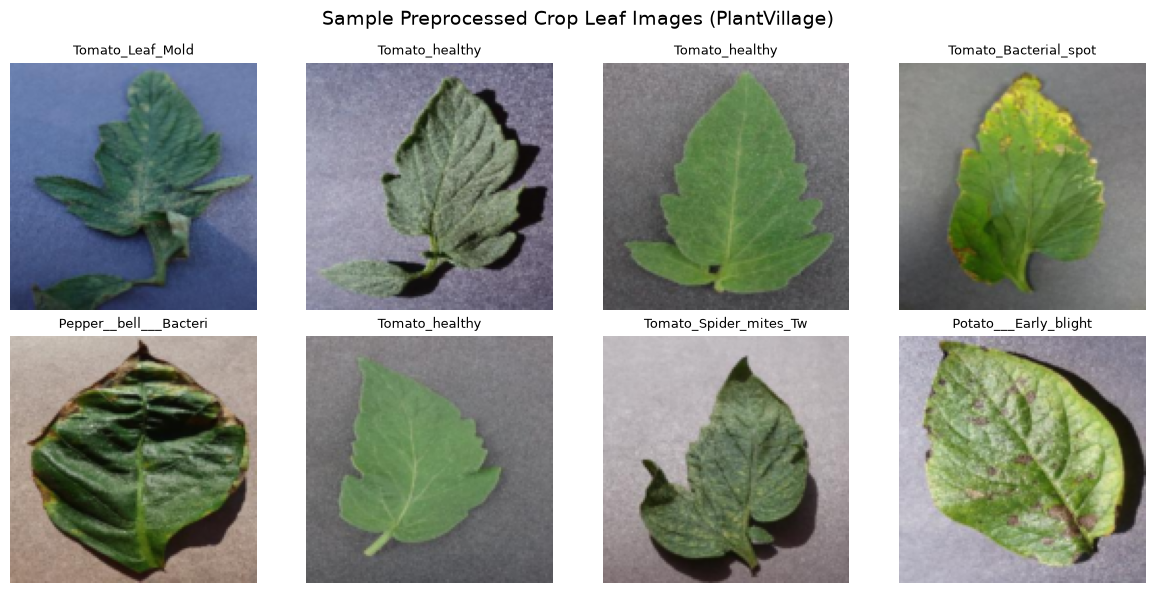

In [3]:
# CELL 3: Visualize Sample Preprocessed Dataset Images
def unnormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img_tensor.numpy().transpose((1, 2, 0))
    img = std * img + mean
    return np.clip(img, 0, 1)

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(unnormalize(images[i]))
    plt.title(class_names[labels[i]][:22], fontsize=9)
    plt.axis("off")
plt.suptitle("Sample Preprocessed Crop Leaf Images (PlantVillage)", fontsize=14)
plt.tight_layout()
plt.show()

In [4]:
# CELL 4: CNN Model Architecture
class CropDiseaseCNN(nn.Module):
    def __init__(self, num_classes):
        super(CropDiseaseCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )
        
    def forward(self, x):
        return self.classifier(self.features(x))

model = CropDiseaseCNN(num_classes=num_classes).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")

CropDiseaseCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): 

In [5]:
# CELL 5: Training & Validation Loop + Save Model & Class Names for app.py
EPOCHS = 10
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("Starting Training...\n")
for epoch in range(EPOCHS):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100
    
    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = val_loss / total_val
    epoch_val_acc = (correct_val / total_val) * 100
    
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%")

# Save weights and class names directly into your VS Code project folder!
torch.save(model.state_dict(), "crop_disease_cnn.pth")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("\nSaved 'crop_disease_cnn.pth' and 'class_names.json' in project folder!")

Starting Training...

Epoch [1/10] | Train Loss: 2.0188, Train Acc: 44.72% | Val Loss: 0.8721, Val Acc: 73.82%
Epoch [2/10] | Train Loss: 1.0561, Train Acc: 63.85% | Val Loss: 0.6727, Val Acc: 78.53%
Epoch [3/10] | Train Loss: 0.8933, Train Acc: 69.20% | Val Loss: 0.4958, Val Acc: 82.74%
Epoch [4/10] | Train Loss: 0.7923, Train Acc: 72.12% | Val Loss: 0.4483, Val Acc: 84.63%
Epoch [5/10] | Train Loss: 0.7207, Train Acc: 74.83% | Val Loss: 0.4254, Val Acc: 86.09%
Epoch [6/10] | Train Loss: 0.6504, Train Acc: 77.01% | Val Loss: 0.3256, Val Acc: 88.37%
Epoch [7/10] | Train Loss: 0.5880, Train Acc: 79.00% | Val Loss: 0.3302, Val Acc: 88.85%
Epoch [8/10] | Train Loss: 0.5310, Train Acc: 81.73% | Val Loss: 0.2545, Val Acc: 91.52%
Epoch [9/10] | Train Loss: 0.4965, Train Acc: 82.53% | Val Loss: 0.2363, Val Acc: 92.15%
Epoch [10/10] | Train Loss: 0.4704, Train Acc: 83.23% | Val Loss: 0.2819, Val Acc: 91.03%

Saved 'crop_disease_cnn.pth' and 'class_names.json' in project folder!


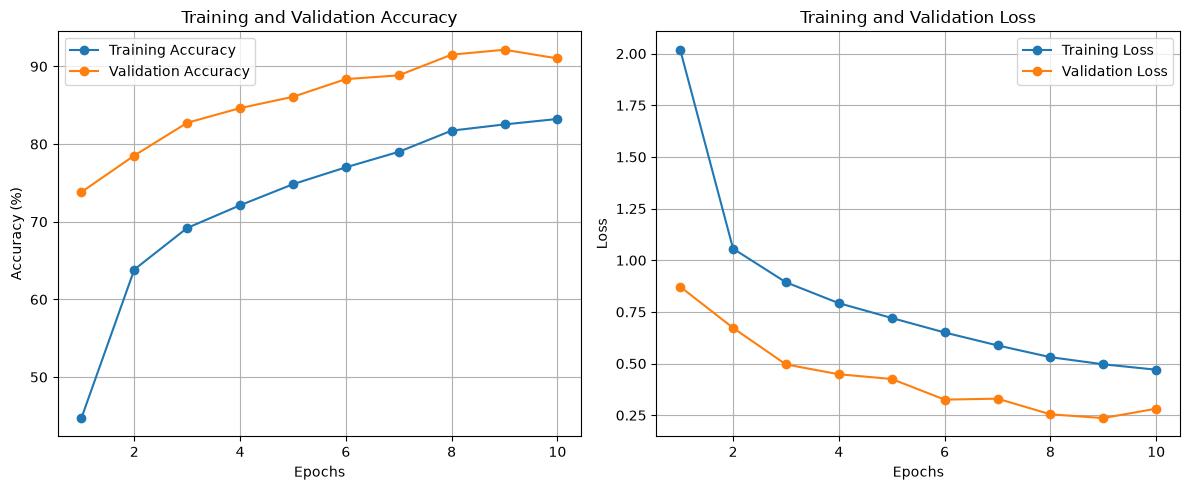

In [6]:
# CELL 6: Plot Accuracy & Loss Curves
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Final Unseen Test Accuracy: 90.02%

=== Classification Report (Precision, Recall, F1-Score) ===
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot     0.9390    0.9167    0.9277        84
                     Pepper__bell___healthy     0.9677    0.9494    0.9585       158
                      Potato___Early_blight     0.8125    0.9811    0.8889       106
                       Potato___Late_blight     0.9792    0.7966    0.8785       118
                           Potato___healthy     1.0000    0.3333    0.5000        18
                      Tomato_Bacterial_spot     0.8047    0.9952    0.8898       207
                        Tomato_Early_blight     0.7347    0.6606    0.6957       109
                         Tomato_Late_blight     0.9029    0.8495    0.8753       186
                           Tomato_Leaf_Mold     0.8725    0.9570    0.9128        93
                  Tomato_Septoria_leaf_spot     0.937

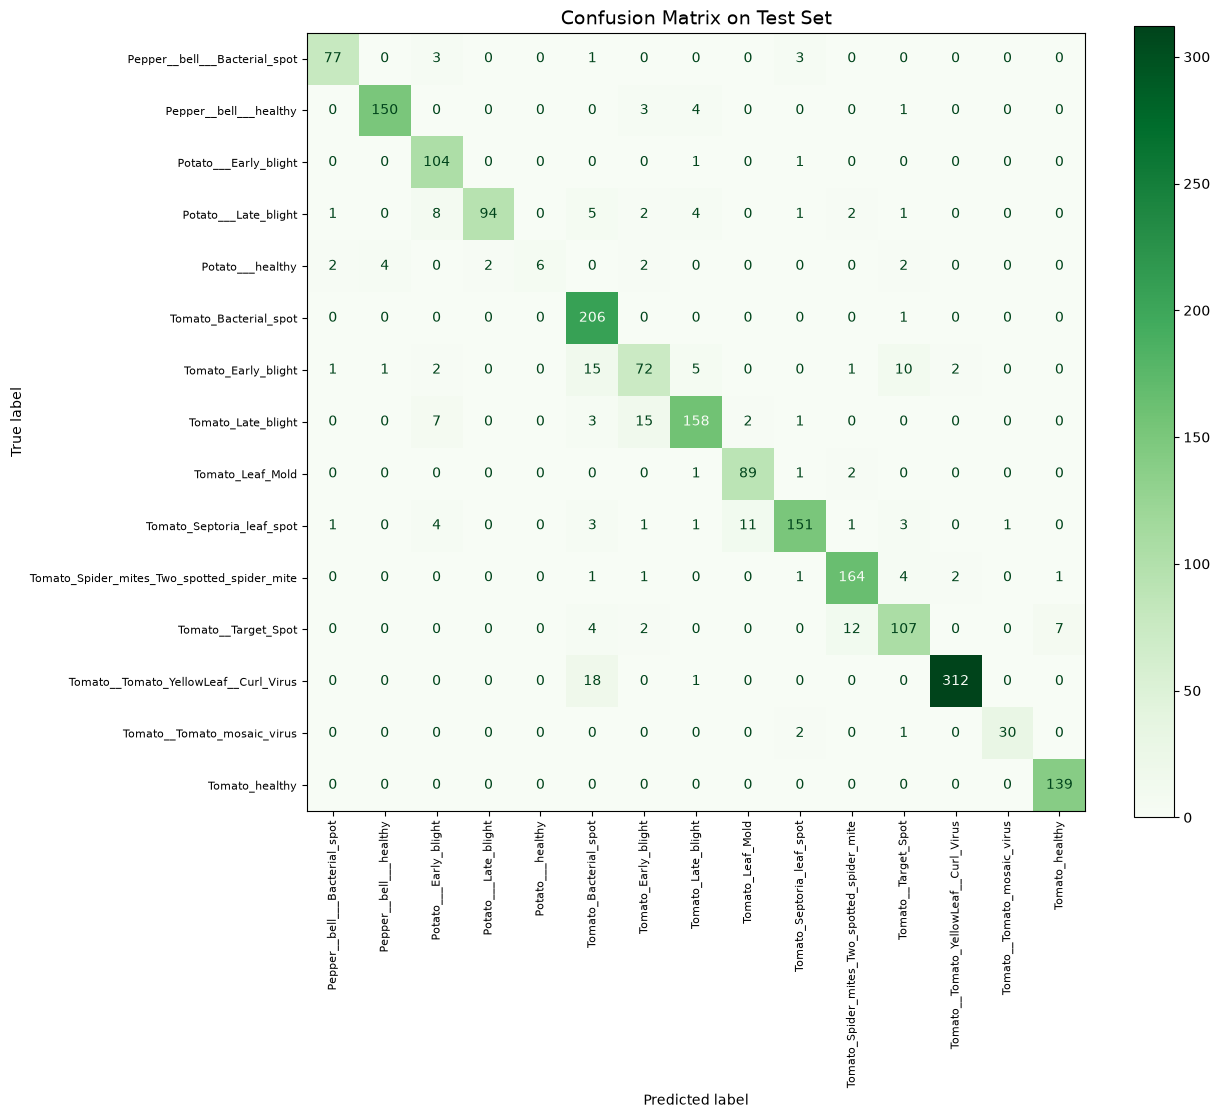

In [8]:
# # CELL 7: Evaluation Results on Unseen Test Data
# from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
# import seaborn as sns

# model.eval()
# all_preds, all_labels = [], []

# with torch.no_grad():
#     for images, labels in test_loader:
#         images = images.to(device)
#         outputs = model(images)
#         _, preds = torch.max(outputs, 1)
        
#         all_preds.extend(preds.cpu().numpy())
#         all_labels.extend(labels.numpy())

# test_acc = accuracy_score(all_labels, all_preds) * 100
# print(f"Final Unseen Test Accuracy: {test_acc:.2f}%\n")

# print("=== Classification Report (Precision, Recall, F1-Score) ===")
# print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# cm = confusion_matrix(all_labels, all_preds)
# plt.figure(figsize=(12, 10))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
#             xticklabels=class_names, yticklabels=class_names)
# plt.title('Confusion Matrix on Test Set', fontsize=14)
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.xticks(rotation=90, fontsize=8)
# plt.yticks(rotation=0, fontsize=8)
# plt.tight_layout()
# plt.show()

# CELL 7: Evaluation Results on Unseen Test Data (No Seaborn/Pandas needed!)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Overall Test Accuracy
test_acc = accuracy_score(all_labels, all_preds) * 100
print(f"Final Unseen Test Accuracy: {test_acc:.2f}%\n")

# Detailed Precision, Recall, and F1-Score Report
print("=== Classification Report (Precision, Recall, F1-Score) ===")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# Confusion Matrix Plot using Matplotlib & Scikit-Learn
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(13, 11))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Greens', ax=ax, xticks_rotation=90, values_format='d')

plt.title('Confusion Matrix on Test Set', fontsize=14)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

Saved test image to project folder: sample_test_Pepper__bell___Bacterial_spot.jpg
Saved test image to project folder: sample_test_Potato___Early_blight.jpg
Saved test image to project folder: sample_test_Tomato_Bacterial_spot.jpg

Testing on sample image (Ground Truth: Pepper__bell___Bacterial_spot):


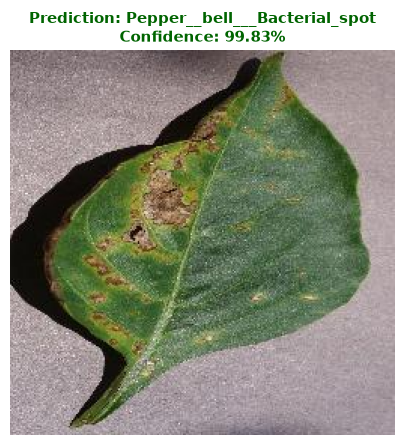

In [9]:
# CELL 8: Offline Single-Image Prediction & Export 3 Sample Images for Website Testing
import shutil
from PIL import Image
import torch.nn.functional as F

def predict_leaf_disease(image_path, model, transform, class_names, device):
    raw_image = Image.open(image_path).convert("RGB")
    input_tensor = transform(raw_image).unsqueeze(0).to(device)
    
    model.eval()
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        
    predicted_class = class_names[predicted_idx.item()]
    confidence_pct = confidence.item() * 100
    
    plt.figure(figsize=(5, 5))
    plt.imshow(raw_image)
    plt.axis("off")
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence_pct:.2f}%", 
              fontsize=11, fontweight='bold', color='darkgreen')
    plt.show()

# Copy 3 sample images from different classes into your project folder for easy website testing
for idx in [0, 2500, 5000]:
    if idx < len(full_dataset.samples):
        src_path, label_idx = full_dataset.samples[idx]
        dest_name = f"sample_test_{class_names[label_idx]}.jpg"
        shutil.copy(src_path, dest_name)
        print(f"Saved test image to project folder: {dest_name}")

# Run prediction on the first sample image inside the notebook
sample_img_path, sample_true_label = full_dataset.samples[0]
print(f"\nTesting on sample image (Ground Truth: {class_names[sample_true_label]}):")
predict_leaf_disease(sample_img_path, model, transform, class_names, device)